3. **Python/data.** Use `lecture_04_examples.ipynb` as a starting point. For each sample size $n\in\{500,10\,000\}$, generate $n$ independent observations $x_1,\ldots,x_n$ from the uniform model on $[0,2]$ in Exercise 2, and set $y_i\coloneqq x_i^2$ for every $i\in\{1,\ldots,n\}$. Keep the model and a reported random seed fixed throughout the comparison.

    1. Define $\widehat F_n(y)\coloneqq n^{-1}\sum_{i=1}^n\mathbf 1_{\{y_i\le y\}}$ for every $y\in\mathbb R$. Plot both empirical CDFs together with the theoretical CDF $F_Y$ from Exercise 2.

    2. Use the same grid $G\coloneqq\{4j/1000:j=0,\ldots,1000\}$ for both sample sizes. Report the maximum absolute difference on this grid,

        $$
        D_n\coloneqq\max_{y\in G}\bigl|\widehat F_n(y)-F_Y(y)\bigr|.
        $$


    3. Tabulate $\widehat F_n^{-1}(u)$ and $F_Y^{-1}(u)$ for each $u\in\{0.1,0.5,0.9\}$. Use `method="inverted_cdf"` in `np.quantile` to match the generalized-inverse definition.

    4. Describe the differences visible in your plots and tables. Does the larger sample have the smaller value of $D_n$ in this run? Explain why a comparison of two simulated samples does not guarantee the same ordering in every run.



In [101]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(20260811)
plt.style.use("seaborn-v0_8-whitegrid")

## (a)
Define $\widehat F_n(y)\coloneqq n^{-1}\sum_{i=1}^n\mathbf 1_{\{y_i\le y\}}$ for every $y\in\mathbb R$. Plot both empirical CDFs together with the theoretical CDF $F_Y$ from Exercise 2.

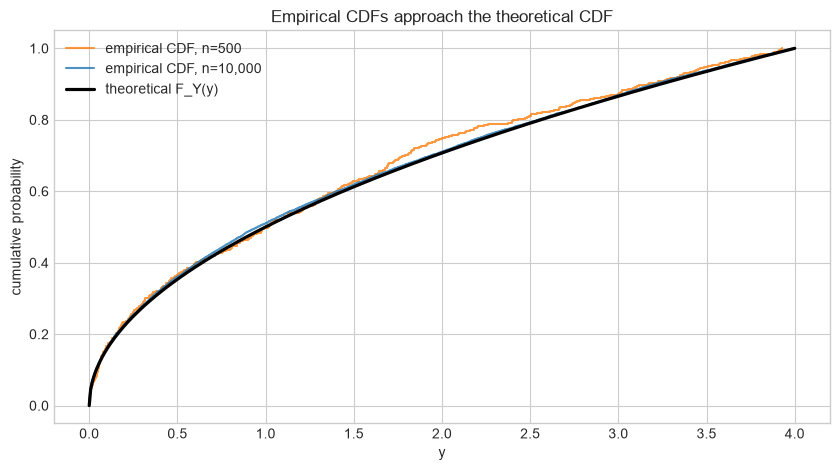

In [102]:
def ecdf(sample):
    ordered = np.sort(sample)
    cumulative = np.arange(1, len(ordered) + 1) / len(ordered)
    return ordered, cumulative

uniform = stats.uniform(loc=0.0, scale=2.0)
fig, ax = plt.subplots(figsize=(8.5, 4.8))

x = {n_samples: uniform.rvs(size=n_samples, random_state=rng) for n_samples in (500, 10000)}
y = {n_samples: x.get(n_samples)**2 for n_samples in x.keys()}


for n_samples, color in [(500, "tab:orange"), (10000, "tab:blue")]:
    y_now = y.get(n_samples)
    ordered, cumulative = ecdf(y_now)
    ax.step(ordered, cumulative, where="post", color=color, alpha=0.8, label=f"empirical CDF, n={n_samples:,}")

cdf_grid = np.linspace(0, 4, 500)
ax.plot(cdf_grid, np.sqrt(cdf_grid)/2, color="black", linewidth=2.3, label="theoretical F_Y(y)")
ax.set_xlabel("y")
ax.set_ylabel("cumulative probability")
ax.set_title("Empirical CDFs approach the theoretical CDF")
ax.legend()
plt.tight_layout()
plt.show()

## (b)
Use the same grid $G\coloneqq\{4j/1000:j=0,\ldots,1000\}$ for both sample sizes. Report the maximum absolute difference on this grid,$$
        D_n\coloneqq\max_{y\in G}\bigl|\widehat F_n(y)-F_Y(y)\bigr|.
        $$

In [103]:
G = np.linspace(0, 4, 1001)
F_true = np.sqrt(G) / 2
for n in [500, 10000]:
    F_hat = np.searchsorted(np.sort(y.get(n)), G, side="right") / n
    D_n = np.max(np.abs(F_hat - F_true))
    print(f"D_n for {n} samples is {np.round(D_n, 5)}")

D_n for 500 samples is 0.04229
D_n for 10000 samples is 0.01277


## (c)
Tabulate $\widehat F_n^{-1}(u)$ and $F_Y^{-1}(u)$ for each $u\in\{0.1,0.5,0.9\}$. Use `method="inverted_cdf"` in `np.quantile` to match the generalized-inverse definition.

In [104]:
us = np.array([0.1, 0.5, 0.9])

for n in [500, 10_000]:
    F_hat = np.searchsorted(np.sort(y.get(n)), G, side="right") / n
    D_n = np.max(np.abs(F_hat - F_true))
    q_hat = np.quantile(y.get(n), us, method="inverted_cdf")
    print(n, "\t", np.round(D_n, 5), "\t", q_hat)

print("theory", "\t"*4, 4 * us**2)

500 	 0.04229 	 [0.04878709 1.01544991 3.17000611]
10000 	 0.01277 	 [0.03700295 0.95340727 3.20305106]
theory 				 [0.04 1.   3.24]
